<img src="https://raw.githubusercontent.com/piddy376/visits-weather-notebooks/main/assets/ECMWF_Core_Logo_RGB.png" alt="ECMWF" height="44"/>

# Typhoon Bavi in two ECMWF forecasts 🌀
### ECMWF open data · IFS and AIFS Single, 0.25° · no account needed

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/piddy376/visits-weather-notebooks/blob/main/china/typhoon_aifs_vs_ifs.ipynb)

ECMWF runs two global forecasts, and both are **open data**: the physics-based **IFS** and the machine-learned
**AIFS Single**. In July 2026 Typhoon Bavi came ashore at Yuhuan, Zhejiang, on 11 July. This notebook takes the
**8 July 2026, 00 UTC run** of both models, follows the storm centre in each forecast, and maps both side by side at
the landfall time, 90 hours ahead, with the track the storm really took.

**What you need:** a Google account (to use Colab). No other account, no fee, nothing to install. Everything runs on Google's computers, so a slow or mobile connection is fine.

| Data | What this notebook uses | Licence |
|---|---|---|
| [ECMWF open data](https://www.ecmwf.int/en/forecasts/datasets/open-data), IFS 0.25° | mean sea level pressure and 10 m wind, run 8 July 2026 00 UTC, 6-hourly to +96 h | CC BY 4.0, © ECMWF |
| ECMWF open data, AIFS Single 0.25° | the same | CC BY 4.0, © ECMWF |

**Tools:** [earthkit](https://earthkit.ecmwf.int), ECMWF's free, open-source Python tools for weather and climate data, with xarray and cartopy.

*Press **Runtime → Run all**. The first run takes a few minutes: installing the tools, then the data.*

> Not an official ECMWF product: a worked example for the ECMWF liaison visit to China, 2026. ECMWF's own open-data portal keeps only the last few
> days; older runs come from the open-data mirror on Amazon Web Services. "What happened" is the start (step 0) of
> each later IFS run, not the official best track, and one run shows one case, not which model is better.

In [ ]:
# Install the open-source tools (Colab / fresh machine). Takes a few minutes the first time.
%pip install -q "earthkit-data[ecmwf-opendata]" earthkit-plots

In [2]:
import pyproj                     # import before earthkit.data (avoids a crash at exit)
import json, time, datetime as dt
from concurrent.futures import ThreadPoolExecutor
import numpy as np, requests
import earthkit.data as ekd
import cartopy.crs as ccrs
import matplotlib.pyplot as plt
import matplotlib.patheffects as pe

## 1 · Choose the storm, the run and the time

In [3]:
STORM = "Bavi"
RUN   = dt.datetime(2026, 7, 8, 0)          # the 00 UTC run of 8 July 2026
WHEN  = 90                                  # hours after the run: 11 July 18 UTC, when Bavi came ashore
START = (16.9, 134.0)                       # where the storm was when the run started (latitude, longitude)
ASHORE = ("Yuhuan", 28.1, 121.3)            # where it came ashore
AREA  = dict(north=36, south=12, west=108, east=140)
STEPS = list(range(0, WHEN + 7, 6))         # every 6 hours, to just after WHEN
valid = RUN + dt.timedelta(hours=WHEN)
print(f"{STORM}: run {RUN:%d %B %Y %H} UTC, map at +{WHEN} h = {valid:%A %d %B %H} UTC")

Bavi: run 08 July 2026 00 UTC, map at +90 h = Saturday 11 July 18 UTC


## 2 · Get both forecasts (ECMWF open data, AWS mirror)

Every open-data file comes with an `.index` that says where each field starts, so the notebook downloads only the
fields it needs: pressure at every step, and the wind at the time of the map.

In [4]:
BASE = "https://ecmwf-forecasts.s3.eu-central-1.amazonaws.com"     # the open-data mirror on AWS, back to 2023

def get(url, headers=None, tries=7):
    for k in range(tries):                       # AWS sometimes answers "503 SlowDown": wait and try again
        try:
            r = requests.get(url, headers=headers, timeout=120)
            if r.status_code in (429, 500, 502, 503, 504):
                raise requests.HTTPError(f"HTTP {r.status_code}")
            r.raise_for_status(); return r
        except requests.RequestException:
            if k == tries - 1: raise
            time.sleep(2 * 2 ** k)

def fields(model, run, step, params):
    """The GRIB bytes of a few fields from one open-data file."""
    stem = f"{BASE}/{run:%Y%m%d}/{run:%H}z/{model}/0p25/oper/{run:%Y%m%d%H}0000-{step}h-oper-fc"
    out = b""
    for line in get(stem + ".index").text.splitlines():
        e = json.loads(line)
        if e["param"] in params:
            a = e["_offset"]
            out += get(stem + ".grib2", {"Range": f"bytes={a}-{a + e['_length'] - 1}"}).content
    return out

def download(target, jobs):
    with ThreadPoolExecutor(8) as pool:          # eight files at a time
        parts = list(pool.map(lambda j: fields(*j), jobs))
    with open(target, "wb") as f:
        f.write(b"".join(parts))
    x = ekd.from_source("file", target).to_xarray()
    x = x.assign_coords(longitude=((x.longitude + 180) % 360) - 180).sortby("longitude").sortby("latitude")
    x = x.sel(latitude=slice(AREA["south"], AREA["north"]), longitude=slice(AREA["west"], AREA["east"]))
    return x.squeeze(drop=True)

msl, wind = {}, {}
for model in ("ifs", "aifs-single"):
    msl[model] = download(f"{model}_msl.grib2", [(model, RUN, s, ["msl"]) for s in STEPS])["msl"] / 100   # hPa
    w = download(f"{model}_wind.grib2", [(model, RUN, WHEN, ["10u", "10v"])])
    wind[model] = np.hypot(*(w[v] for v in list(w.data_vars)[:2]))                                      # m/s
    print(f"{model}: {len(STEPS)} pressure fields and the wind at +{WHEN} h")

# what happened: the starting state (step 0) of each IFS run every 6 hours, from RUN to just after WHEN
times = [RUN + dt.timedelta(hours=s) for s in STEPS]
an = download("analysis_msl.grib2", [("ifs", t, 0, ["msl"]) for t in times])["msl"] / 100
print(f"what happened: {len(times)} analyses, {times[0]:%d %b %H} to {times[-1]:%d %b %H} UTC")

ifs: 17 pressure fields and the wind at +90 h


aifs-single: 17 pressure fields and the wind at +90 h


what happened: 17 analyses, 08 Jul 00 to 12 Jul 00 UTC


## 3 · Follow the storm centre

The centre is the lowest pressure within 3° of where it was 6 hours earlier.

In [5]:
def track(p, start, r=3.0):
    p = p.transpose(..., "latitude", "longitude")
    lat, lon = start; out = []
    for k in range(p.shape[0]):
        box = p[k].sel(latitude=slice(lat - r, lat + r), longitude=slice(lon - r, lon + r))
        i, j = np.unravel_index(np.nanargmin(box.values), box.shape)
        lat, lon = float(box.latitude[i]), float(box.longitude[j])
        out.append((lat, lon, float(box.values[i, j])))
    return np.array(out)

def km(a, b):                                   # great-circle distance between two (lat, lon) points
    la1, lo1, la2, lo2 = np.radians([a[0], a[1], b[0], b[1]])
    return 6371 * 2 * np.arcsin(np.sqrt(np.sin((la2 - la1) / 2) ** 2 +
                                        np.cos(la1) * np.cos(la2) * np.sin((lo2 - lo1) / 2) ** 2))

k = STEPS.index(WHEN)
tracks = {"analysis": track(an, START)} | {m: track(msl[m], START) for m in msl}
for m in ("ifs", "aifs-single"):
    t = tracks[m]
    print(f"{m:12s} at +{WHEN} h: {t[k, 0]:.1f}N {t[k, 1]:.1f}E, {t[k, 2]:.0f} hPa, "
          f"{km(t[k], tracks['analysis'][k]):.0f} km from where the storm was")
print(f"{'what happened':12s}: {tracks['analysis'][k, 0]:.1f}N {tracks['analysis'][k, 1]:.1f}E, "
      f"{tracks['analysis'][k, 2]:.0f} hPa")

ifs          at +90 h: 27.5N 117.8E, 975 hPa, 303 km from where the storm was
aifs-single  at +90 h: 27.8N 121.0E, 966 hPa, 122 km from where the storm was
what happened: 28.8N 120.5E, 972 hPa


## 4 · Side by side at the landfall time

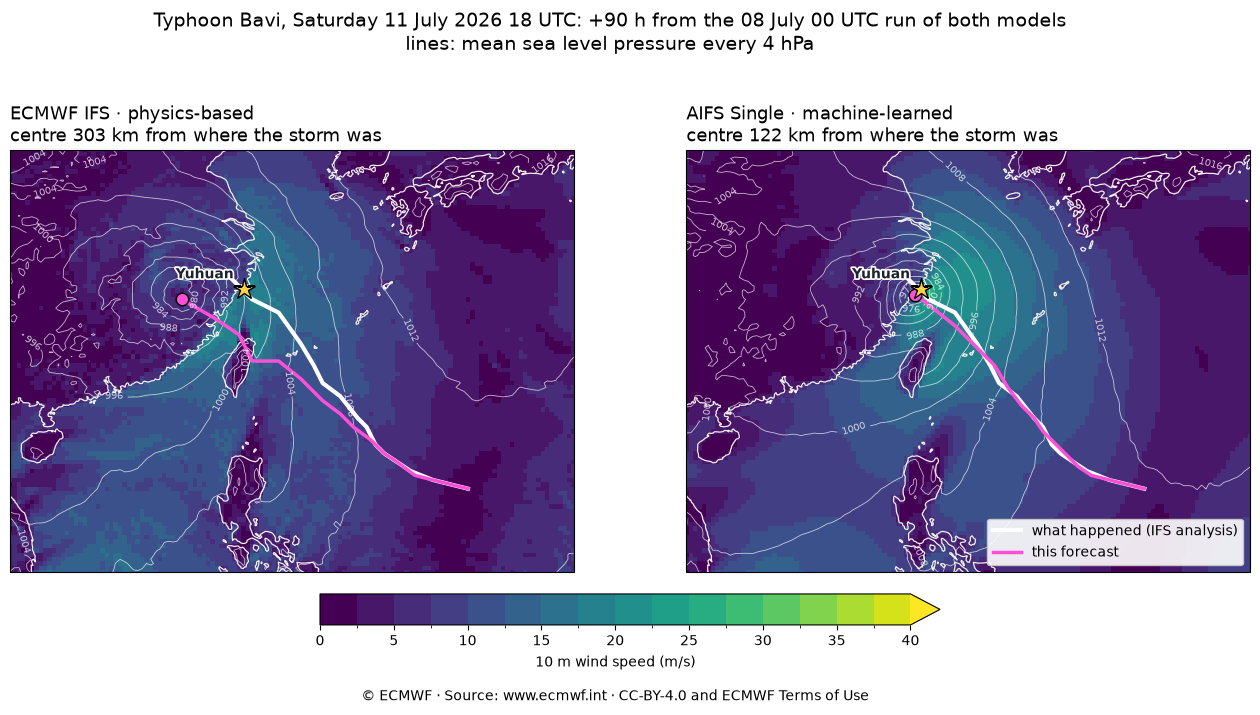

In [6]:
from matplotlib.colors import BoundaryNorm
levels = np.arange(0, 42.5, 2.5)
norm = BoundaryNorm(levels, 256, extend="max")
fig, axs = plt.subplots(1, 2, figsize=(16, 7), subplot_kw=dict(projection=ccrs.PlateCarree()))
for ax, m, title in ((axs[0], "ifs", "ECMWF IFS · physics-based"), (axs[1], "aifs-single", "AIFS Single · machine-learned")):
    ax.set_extent([AREA["west"], AREA["east"], AREA["south"], AREA["north"]], crs=ccrs.PlateCarree())
    w, p = wind[m], msl[m].isel(step=k) if "step" in msl[m].dims else msl[m][k]
    sh = ax.pcolormesh(w.longitude, w.latitude, w, cmap="viridis", norm=norm, shading="auto")
    cs = ax.contour(p.longitude, p.latitude, p, levels=np.arange(900, 1040, 4), colors="white", linewidths=0.6, alpha=0.7)
    ax.clabel(cs, fontsize=7, fmt="%d")
    ax.coastlines("50m", color="#f0f0f0", linewidth=0.9)               # coastlines only, no boundaries
    a, t = tracks["analysis"], tracks[m]
    ax.plot(a[:k + 1, 1], a[:k + 1, 0], "-", color="white", lw=3, label="what happened (IFS analysis)")
    ax.plot(t[:k + 1, 1], t[:k + 1, 0], "-", color="#ff4fd8", lw=2.5, label="this forecast")
    ax.plot(t[k, 1], t[k, 0], "o", color="#ff4fd8", mec="k", ms=9)
    ax.plot(ASHORE[2], ASHORE[1], "*", color="#ffd23f", mec="k", ms=16, zorder=5)
    ax.text(ASHORE[2] - 0.6, ASHORE[1] + 0.6, ASHORE[0], ha="right", fontsize=10, fontweight="bold", color="#1d2230",
            path_effects=[pe.withStroke(linewidth=2.5, foreground="white")])
    ax.set_title(f"{title}\ncentre {km(t[k], a[k]):.0f} km from where the storm was", fontsize=13, loc="left")
axs[1].legend(loc="lower right", fontsize=10, framealpha=0.9)
fig.colorbar(sh, ax=axs, orientation="horizontal", shrink=0.5, pad=0.04,
             label="10 m wind speed (m/s)\n\n© ECMWF · Source: www.ecmwf.int · CC-BY-4.0 and ECMWF Terms of Use")
fig.suptitle(f"Typhoon {STORM}, {valid:%A %d %B %Y %H} UTC: +{WHEN} h from the {RUN:%d %B %H} UTC run of both models"
             "\nlines: mean sea level pressure every 4 hPa", fontsize=14, y=1.06)
fig.savefig("typhoon_aifs_vs_ifs.png", dpi=110, bbox_inches="tight")
plt.show()

## 5 · Your turn 🌍

- **Earlier in the forecast:** `WHEN = 48` or `72`, with the storm still at sea.
- **An earlier run:** `RUN = dt.datetime(2026, 7, 6)` with `WHEN = 138` and `START = (14.3, 145.0)`. Both models are
  further out five and a half days ahead.
- **Another typhoon:** Matmo came ashore near Zhanjiang, Guangdong: `STORM = "Matmo"`, `RUN = dt.datetime(2025, 10, 3)`,
  `WHEN = 54`, `ASHORE = ("Zhanjiang", 20.4, 110.5)`, and set `START` to its position at the start of the run.
- **Rain instead of wind:** ask for `"tp"` (total precipitation since the start, metres) in place of `"10u", "10v"`.

### Data & licence
ECMWF Open Data is free under **Creative Commons CC-BY-4.0**:
`© ECMWF · Source: www.ecmwf.int · CC-BY-4.0 and ECMWF Terms of Use`. No account, no key. Runs older than a few days come from the [AWS open-data mirror](https://registry.opendata.aws/ecmwf-forecasts/).

[ECMWF open data](https://www.ecmwf.int/en/forecasts/datasets/open-data) · [earthkit](https://earthkit.ecmwf.int)